In [1]:
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    BaggingClassifier,
    AdaBoostClassifier,
    RandomForestClassifier,
    VotingClassifier,
)
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 110,
})
pd.set_option("display.max_columns", 50)


def load_ecommerce_churn() -> tuple[pd.DataFrame, str]:
    """Load E-Commerce Churn dataset from local Excel/CSV or public GitHub mirror."""
    xlsx_path = Path("E Commerce Dataset.xlsx")
    csv_path = Path("E Commerce Dataset.csv")

    if xlsx_path.exists():
        xl = pd.ExcelFile(xlsx_path)
        sheet = "E Comm" if "E Comm" in xl.sheet_names else xl.sheet_names[-1]
        return pd.read_excel(xlsx_path, sheet_name=sheet), f"Local Excel ({xlsx_path.name}, sheet='{sheet}')"

    if csv_path.exists():
        return pd.read_csv(csv_path), f"Local CSV ({csv_path.name})"

    mirror_urls = [
        "https://raw.githubusercontent.com/nprihandina/ecommerce_churn_prediction/main/E%20Commerce%20Dataset.xlsx",
        "https://raw.githubusercontent.com/LingAdeu/customer-churn-prediction/main/data/E%20Commerce%20Dataset.xlsx",
    ]
    for url in mirror_urls:
        try:
            urllib.request.urlretrieve(url, xlsx_path)
            xl = pd.ExcelFile(xlsx_path)
            sheet = "E Comm" if "E Comm" in xl.sheet_names else xl.sheet_names[-1]
            return pd.read_excel(xlsx_path, sheet_name=sheet), f"Downloaded mirror ({url})"
        except Exception:
            continue

    raise FileNotFoundError(
        "Could not locate 'E Commerce Dataset.xlsx' or '.csv' locally, and mirror download failed."
    )


df_raw, source_desc = load_ecommerce_churn()
print(f"Loaded from: {source_desc}")
print(f"Raw shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
display(df_raw.head(3))


Loaded from: Local Excel (E Commerce Dataset.xlsx, sheet='E Comm')
Raw shape: 5,630 rows x 20 columns


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28


Unique CustomerID count: 5630 out of 5630
Exact duplicate rows (with CustomerID): 0
Rows sharing identical feature+target profiles after dropping CustomerID: 557
-> Retained because every row corresponds to a distinct CustomerID (50001-55630); dropping them would distort true churn prevalence.


,Missing_Count,Missing_Pct,Dtype
DaySinceLastOrder,307,5.45,float64
OrderAmountHikeFromlastYear,265,4.71,float64
Tenure,264,4.69,float64
OrderCount,258,4.58,float64
CouponUsed,256,4.55,float64
HourSpendOnApp,255,4.53,float64
WarehouseToHome,251,4.46,float64



Extreme WarehouseToHome records (> 50 km):


,Churn,WarehouseToHome,Tenure,CityTier
1309,0,126.0,25.0,3
4124,0,127.0,26.0,3


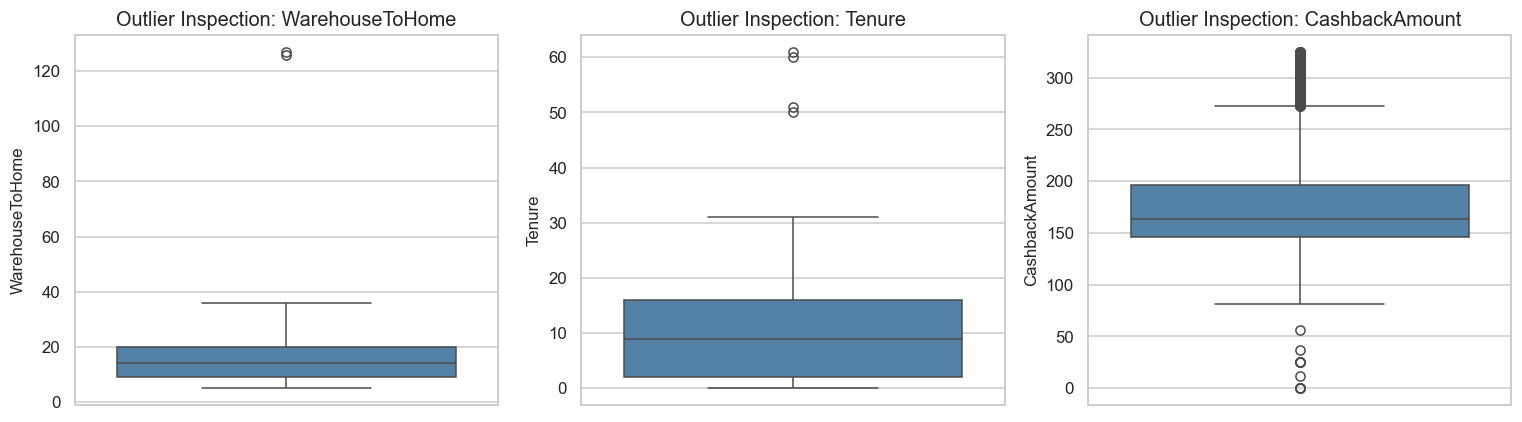

Removing 2 extreme WarehouseToHome anomalies (>100 km); retaining valid upper-tail Tenure/Address values.
Cleaned dataset shape: 5,628 rows x 19 columns


In [2]:
print("Unique CustomerID count:", df_raw["CustomerID"].nunique(), "out of", len(df_raw))
print("Exact duplicate rows (with CustomerID):", df_raw.duplicated().sum())

# Drop non-predictive CustomerID
df = df_raw.drop(columns=["CustomerID"]).copy()

# Deterministic synonym standardization (zero leakage)
df["PreferredLoginDevice"] = df["PreferredLoginDevice"].replace({"Phone": "Mobile Phone"})
df["PreferredPaymentMode"] = df["PreferredPaymentMode"].replace({
    "CC": "Credit Card",
    "Cash on Delivery": "COD",
})
df["PreferedOrderCat"] = df["PreferedOrderCat"].replace({"Mobile": "Mobile Phone"})

# Check duplicates after dropping CustomerID
dup_features = df.duplicated().sum()
print(f"Rows sharing identical feature+target profiles after dropping CustomerID: {dup_features}")
print("-> Retained because every row corresponds to a distinct CustomerID (50001-55630); dropping them would distort true churn prevalence.")

# Missing values audit
missing_tbl = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Pct": (df.isna().sum() / len(df) * 100).round(2),
    "Dtype": df.dtypes.astype(str),
})
display(missing_tbl[missing_tbl["Missing_Count"] > 0].sort_values("Missing_Count", ascending=False))

# Outlier audit on key continuous features
print("\nExtreme WarehouseToHome records (> 50 km):")
display(df[df["WarehouseToHome"] > 50][["Churn", "WarehouseToHome", "Tenure", "CityTier"]])

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["WarehouseToHome", "Tenure", "CashbackAmount"]):
    sns.boxplot(y=df[col], ax=ax, color="steelblue")
    ax.set_title(f"Outlier Inspection: {col}")
plt.tight_layout()
plt.show()

# Remove the 2 extreme WarehouseToHome anomalies (> 100 km) so MinMaxScaler isn't compressed
wth_anomaly = df["WarehouseToHome"] > 100
print(f"Removing {wth_anomaly.sum()} extreme WarehouseToHome anomalies (>100 km); retaining valid upper-tail Tenure/Address values.")
df_clean = df.loc[~wth_anomaly].copy().reset_index(drop=True)
print(f"Cleaned dataset shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")


Churn class counts:
  Retained (0): 4,680 (83.16%)
  Churned (1): 948 (16.84%)


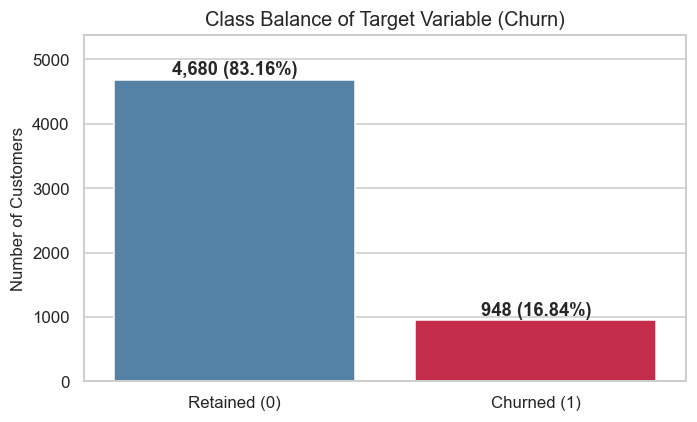

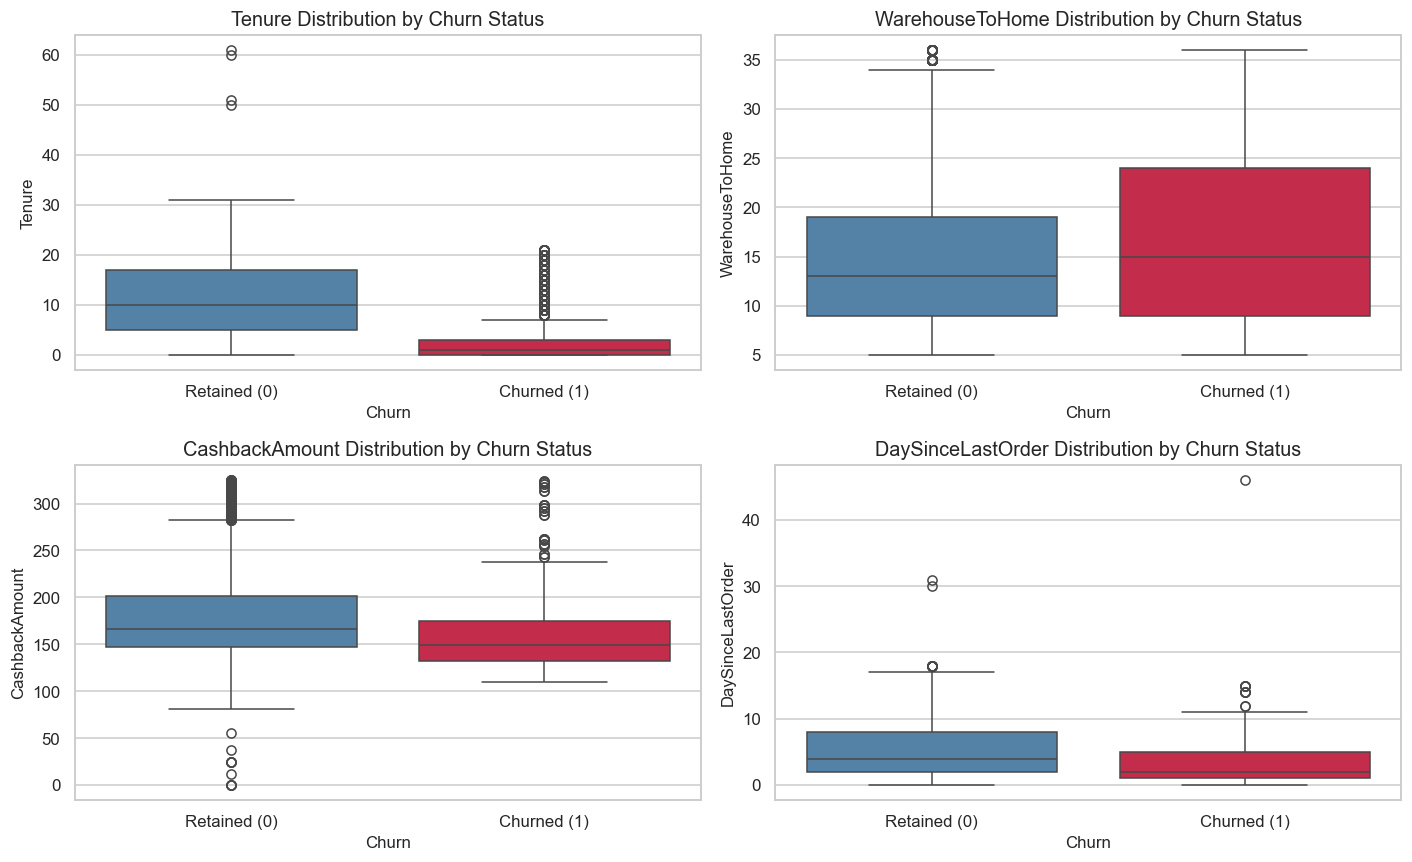

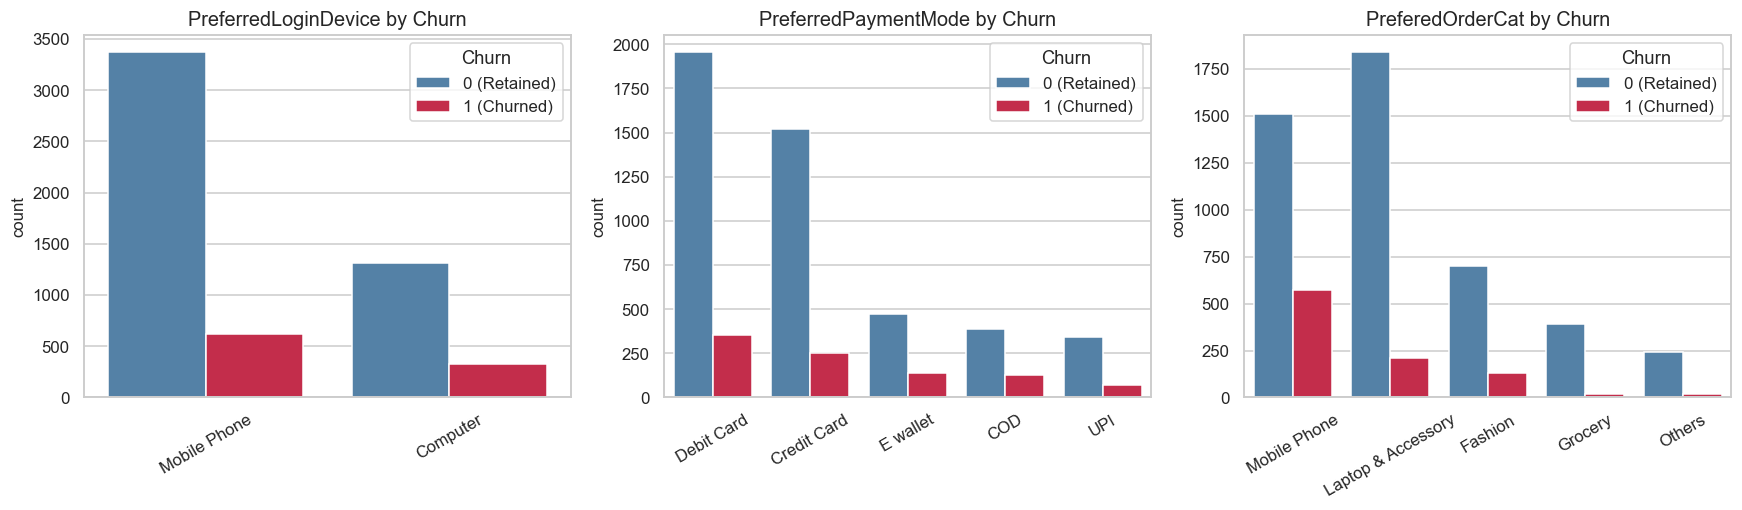

In [3]:
# 1. Target Class Balance
churn_counts = df_clean["Churn"].value_counts().sort_index()
churn_pcts = (churn_counts / len(df_clean) * 100).round(2)
print("Churn class counts:")
for cls in churn_counts.index:
    label = "Retained (0)" if cls == 0 else "Churned (1)"
    print(f"  {label}: {churn_counts[cls]:,} ({churn_pcts[cls]}%)")

fig, ax = plt.subplots(figsize=(6.5, 4))
sns.barplot(
    x=["Retained (0)", "Churned (1)"],
    y=churn_counts.values,
    hue=["Retained (0)", "Churned (1)"],
    palette=["steelblue", "crimson"],
    legend=False,
    ax=ax,
)
ax.set_title("Class Balance of Target Variable (Churn)")
ax.set_ylabel("Number of Customers")
for i, (cnt, pct) in enumerate(zip(churn_counts.values, churn_pcts.values)):
    ax.text(i, cnt + 80, f"{cnt:,} ({pct}%)", ha="center", fontweight="bold")
ax.set_ylim(0, churn_counts.max() * 1.15)
plt.tight_layout()
plt.show()

# 2. Key Numerical Features vs Churn
key_num_eda = ["Tenure", "WarehouseToHome", "CashbackAmount", "DaySinceLastOrder"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), key_num_eda):
    sns.boxplot(
        data=df_clean,
        x="Churn",
        y=col,
        hue="Churn",
        palette=["steelblue", "crimson"],
        legend=False,
        ax=ax,
    )
    ax.set_title(f"{col} Distribution by Churn Status")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Retained (0)", "Churned (1)"])
plt.tight_layout()
plt.show()

# 3. Categorical Features & Churn Rate
key_cat_eda = ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, col in zip(axes, key_cat_eda):
    order = df_clean[col].value_counts().index
    sns.countplot(data=df_clean, x=col, hue="Churn", order=order, palette=["steelblue", "crimson"], ax=ax)
    ax.set_title(f"{col} by Churn")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Churn", labels=["0 (Retained)", "1 (Churned)"])
plt.tight_layout()
plt.show()


In [4]:
X = df_clean.drop(columns=["Churn"]).copy()
y = df_clean["Churn"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"X_train: {X_train.shape} | Churn rate: {y_train.mean()*100:.2f}%")
print(f"X_test : {X_test.shape}  | Churn rate: {y_test.mean()*100:.2f}%")


X_train: (4502, 18) | Churn rate: 16.84%
X_test : (1126, 18)  | Churn rate: 16.87%


In [5]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

assert len(num_cols) + len(cat_cols) == X_train.shape[1], "Column classification mismatch!"
print(f"Numerical features ({len(num_cols)}): {num_cols}")
print(f"Categorical features ({len(cat_cols)}): {cat_cols}")

# 1. Numerical pipeline: Median imputation -> MinMaxScaler [0, 1]
num_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
])

# Attribute inspection: SimpleImputer(strategy="median") on training numerical data
num_imputer_inspect = SimpleImputer(strategy="median")
num_imputer_inspect.fit(X_train[num_cols])

imputer_stats_df = pd.DataFrame({
    "Feature": num_cols,
    "Learned_Median (.statistics_)": num_imputer_inspect.statistics_,
})
print("\nLearned medians stored in SimpleImputer.statistics_:")
display(imputer_stats_df)

# 2. Categorical pipeline: Most-frequent imputation -> OneHotEncoder
cat_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

# Sparse matrix inspection: OneHotEncoder() on training categorical data
cat_imputed_train = SimpleImputer(strategy="most_frequent").fit_transform(X_train[cat_cols])
ohe_inspect = OneHotEncoder(handle_unknown="ignore")
ohe_output = ohe_inspect.fit_transform(cat_imputed_train)

sparsity_pct = (1.0 - ohe_output.nnz / (ohe_output.shape[0] * ohe_output.shape[1])) * 100
print(f"\nOneHotEncoder output type(): {type(ohe_output)}")
print(f"OneHotEncoder output shape: {ohe_output.shape} | Sparsity (zeros): {sparsity_pct:.2f}%")


Numerical features (13): ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
Categorical features (5): ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']

Learned medians stored in SimpleImputer.statistics_:


,Feature,Learned_Median (.statistics_)
0,Tenure,9.000
1,CityTier,1.000
2,WarehouseToHome,14.000
3,HourSpendOnApp,3.000
4,NumberOfDeviceRegistered,4.000
5,SatisfactionScore,3.000
6,NumberOfAddress,3.000
7,Complain,0.000
8,OrderAmountHikeFromlastYear,15.000
9,CouponUsed,1.000



OneHotEncoder output type(): <class 'scipy.sparse._csr.csr_matrix'>
OneHotEncoder output shape: (4502, 17) | Sparsity (zeros): 70.59%


In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols),
    ],
    remainder="drop",
)

master_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

master_pipeline.fit(X_train, y_train)
y_pred_master = master_pipeline.predict(X_test)
print(f"Master Pipeline Test Accuracy: {accuracy_score(y_test, y_pred_master):.4f}")
print(f"Master Pipeline Test F1-Score: {f1_score(y_test, y_pred_master):.4f}")
print(f"Transformed feature count: {master_pipeline.named_steps['preprocessor'].transform(X_train).shape[1]}")


Master Pipeline Test Accuracy: 0.8961
Master Pipeline Test F1-Score: 0.6087
Transformed feature count: 30


,Model,Train_Acc,Test_Acc,Train_F1,Test_F1,Acc_Gap (Train - Test)
0,"DecisionTree (max_depth=1, High Bias)",0.8390,0.8410,0.5802,0.5728,-0.0021
1,"DecisionTree (max_depth=6, Balanced)",0.9098,0.9059,0.6605,0.6536,0.0040
2,"DecisionTree (max_depth=None, High Variance)",1.0000,0.9813,1.0000,0.9455,0.0187


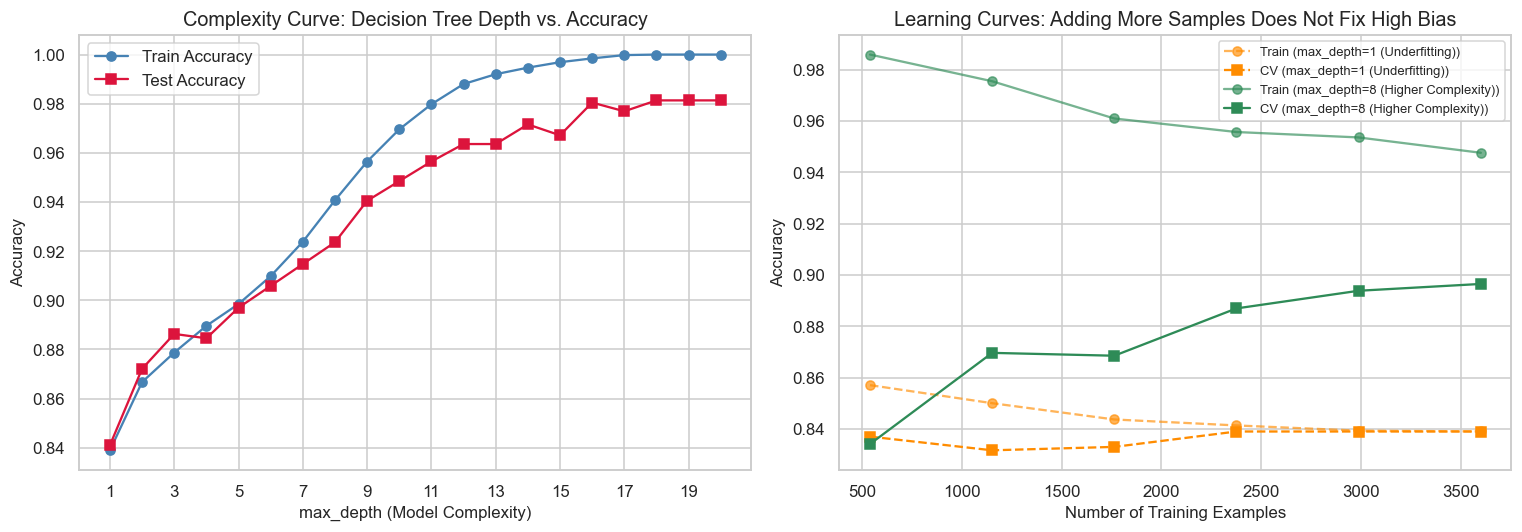

In [7]:
def eval_clf(model, X_tr, y_tr, X_te, y_te, name: str) -> dict:
    p_tr = model.predict(X_tr)
    p_te = model.predict(X_te)
    return {
        "Model": name,
        "Train_Acc": accuracy_score(y_tr, p_tr),
        "Test_Acc": accuracy_score(y_te, p_te),
        "Train_F1": f1_score(y_tr, p_tr),
        "Test_F1": f1_score(y_te, p_te),
        "Acc_Gap (Train - Test)": accuracy_score(y_tr, p_tr) - accuracy_score(y_te, p_te),
    }


depth_configs = [
    ("DecisionTree (max_depth=1, High Bias)", 1),
    ("DecisionTree (max_depth=6, Balanced)", 6),
    ("DecisionTree (max_depth=None, High Variance)", None),
]

bv_rows = []
for label, d in depth_configs:
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)),
    ])
    pipe.fit(X_train, y_train)
    bv_rows.append(eval_clf(pipe, X_train, y_train, X_test, y_test, label))

bv_df = pd.DataFrame(bv_rows)
display(bv_df.round(4))

# Complexity curve across max_depth 1..20
depths = list(range(1, 21))
tr_acc_curve, te_acc_curve = [], []
for d in depths:
    p = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)),
    ])
    p.fit(X_train, y_train)
    tr_acc_curve.append(accuracy_score(y_train, p.predict(X_train)))
    te_acc_curve.append(accuracy_score(y_test, p.predict(X_test)))

# Learning curves for max_depth=1 (underfitting) vs max_depth=8 (higher complexity)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(depths, tr_acc_curve, "o-", label="Train Accuracy", color="steelblue")
axes[0].plot(depths, te_acc_curve, "s-", label="Test Accuracy", color="crimson")
axes[0].set_title("Complexity Curve: Decision Tree Depth vs. Accuracy")
axes[0].set_xlabel("max_depth (Model Complexity)")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(depths[::2])
axes[0].legend()

for d, color, title_lbl in [(1, "darkorange", "max_depth=1 (Underfitting)"), (8, "seagreen", "max_depth=8 (Higher Complexity)")]:
    lc_pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)),
    ])
    train_sizes, train_scores, val_scores = learning_curve(
        lc_pipe,
        X_train,
        y_train,
        train_sizes=np.linspace(0.15, 1.0, 6),
        cv=5,
        scoring="accuracy",
        n_jobs=-1,
    )
    ls_style = "--" if d == 1 else "-"
    axes[1].plot(train_sizes, train_scores.mean(axis=1), f"o{ls_style}", color=color, alpha=0.65, label=f"Train ({title_lbl})")
    axes[1].plot(train_sizes, val_scores.mean(axis=1), f"s{ls_style}", color=color, label=f"CV ({title_lbl})")

axes[1].set_title("Learning Curves: Adding More Samples Does Not Fix High Bias")
axes[1].set_xlabel("Number of Training Examples")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()


#### Analytical Questions (Part 3):
1. **What happens to bias and variance as model complexity increases?**  
   - **Bias decreases:** More complex models (e.g., deeper trees, higher-degree polynomials) make fewer restrictive assumptions and can represent intricate non-linear decision boundaries, reducing systematic underfitting error.
   - **Variance increases:** Greater flexibility allows the model to react strongly to random fluctuations and noise in a specific training sample, widening the train–test performance gap (overfitting).
   - **Total Expected Error:** Follows a U-shaped curve—initially falling as bias drops, then rising once variance dominates beyond the optimal complexity sweet spot.

2. **If a model is underfitting the training data, why does increasing model complexity resolve it whereas simply adding more training examples does not?**  
   - Underfitting occurs because the hypothesis space is **too restrictive** (high bias) to capture the underlying signal even on the data it has already seen. As demonstrated in the learning curve above, `DecisionTreeClassifier(max_depth=1)` can make only a **single axis-aligned split** (`Tenure`). Feeding it 500 or 4,500 examples leaves both its training and CV accuracy plateaued near ~`83–85%` because a 1-split stump is structurally incapable of modeling multi-feature churn interactions (`Tenure` + `Complain` + `CashbackAmount` + `DaySinceLastOrder`).
   - Increasing model complexity (e.g., increasing `max_depth` from `1` to `6–8`) expands the hypothesis space so the model can capture these interactions, raising both training and generalization accuracy.


,Penalty,Train_Acc,Test_Acc,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC,Zero_Coefs (|w|<=1e-6),Total_Features,L2_Norm_||w||2
0,L2 (Ridge),0.8898,0.8970,0.8364,0.4842,0.6133,0.8851,0,30,10.8158
1,L1 (Lasso),0.8952,0.8988,0.8220,0.5105,0.6299,0.8898,3,30,14.3833
2,ElasticNet (l1_ratio=0.5),0.8920,0.8988,0.8393,0.4947,0.6225,0.8877,3,30,12.1453


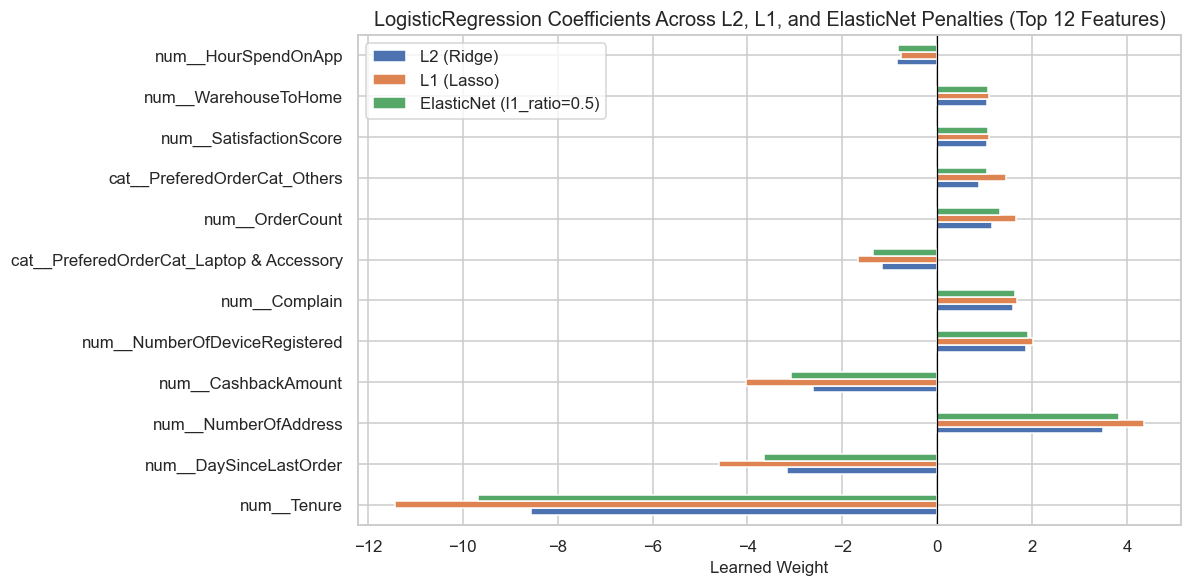

In [8]:
reg_configs = {
    "L2 (Ridge)": {"penalty": "l2"},
    "L1 (Lasso)": {"penalty": "l1"},
    "ElasticNet (l1_ratio=0.5)": {"penalty": "elasticnet", "l1_ratio": 0.5},
}

reg_rows = []
coef_records = {}

for name, params in reg_configs.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            solver="saga",
            max_iter=2000,
            C=1.0,
            random_state=RANDOM_STATE,
            **params,
        )),
    ])
    pipe.fit(X_train, y_train)
    p_tr = pipe.predict(X_train)
    p_te = pipe.predict(X_test)
    prob_te = pipe.predict_proba(X_test)[:, 1]
    coefs = pipe.named_steps["classifier"].coef_.ravel()
    coef_records[name] = coefs

    reg_rows.append({
        "Penalty": name,
        "Train_Acc": accuracy_score(y_train, p_tr),
        "Test_Acc": accuracy_score(y_test, p_te),
        "Test_Precision": precision_score(y_test, p_te),
        "Test_Recall": recall_score(y_test, p_te),
        "Test_F1": f1_score(y_test, p_te),
        "Test_ROC_AUC": roc_auc_score(y_test, prob_te),
        "Zero_Coefs (|w|<=1e-6)": int(np.sum(np.abs(coefs) <= 1e-6)),
        "Total_Features": len(coefs),
        "L2_Norm_||w||2": float(np.linalg.norm(coefs, ord=2)),
    })

reg_df = pd.DataFrame(reg_rows)
display(reg_df.round(4))

# Visualize coefficient magnitudes & sparsity
feat_names = master_pipeline.named_steps["preprocessor"].get_feature_names_out()
coef_comp = pd.DataFrame(coef_records, index=feat_names)
top_idx = coef_comp.abs().max(axis=1).sort_values(ascending=False).head(12).index

fig, ax = plt.subplots(figsize=(11, 5.5))
coef_comp.loc[top_idx].plot(kind="barh", ax=ax)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("LogisticRegression Coefficients Across L2, L1, and ElasticNet Penalties (Top 12 Features)")
ax.set_xlabel("Learned Weight")
plt.tight_layout()
plt.show()


In [9]:
bagging_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=200,
        bootstrap=True,
        oob_score=True,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )),
])

pasting_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=200,
        bootstrap=False,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )),
])

bagging_pipe.fit(X_train, y_train)
pasting_pipe.fit(X_train, y_train)

oob_acc = bagging_pipe.named_steps["classifier"].oob_score_
bag_pred = bagging_pipe.predict(X_test)
pas_pred = pasting_pipe.predict(X_test)

bag_test_acc = accuracy_score(y_test, bag_pred)
pas_test_acc = accuracy_score(y_test, pas_pred)

print(f"Bagging OOB Accuracy (.oob_score_) : {oob_acc:.4f}")
print(f"Bagging Test Accuracy              : {bag_test_acc:.4f} (Diff vs OOB: {bag_test_acc - oob_acc:+.4f})")
print(f"Pasting Test Accuracy (bootstrap=False): {pas_test_acc:.4f}")

bag_summary = pd.DataFrame([
    {
        "Ensemble": "Bagging (bootstrap=True)",
        "OOB_Score": oob_acc,
        "Test_Accuracy": bag_test_acc,
        "Test_Precision": precision_score(y_test, bag_pred),
        "Test_Recall": recall_score(y_test, bag_pred),
        "Test_F1": f1_score(y_test, bag_pred),
    },
    {
        "Ensemble": "Pasting (bootstrap=False)",
        "OOB_Score": np.nan,
        "Test_Accuracy": pas_test_acc,
        "Test_Precision": precision_score(y_test, pas_pred),
        "Test_Recall": recall_score(y_test, pas_pred),
        "Test_F1": f1_score(y_test, pas_pred),
    },
])
display(bag_summary.round(4))


Bagging OOB Accuracy (.oob_score_) : 0.9745
Bagging Test Accuracy              : 0.9867 (Diff vs OOB: +0.0122)
Pasting Test Accuracy (bootstrap=False): 0.9778


,Ensemble,OOB_Score,Test_Accuracy,Test_Precision,Test_Recall,Test_F1
0,Bagging (bootstrap=True),0.9745,0.9867,0.9781,0.9421,0.9598
1,Pasting (bootstrap=False),NaN,0.9778,0.9365,0.9316,0.9340


#### Analytical Questions (Part 4 — Bagging & Pasting):
1. **What does setting `n_jobs=-1` instruct `scikit-learn` to do?**  
   It instructs `scikit-learn` (via `joblib`) to utilize **all available CPU cores/processors in parallel** when training and querying the ensemble's independent base estimators, reducing wall-clock execution time.
2. **Which ensemble technique is used when `bootstrap=False` is set in `BaggingClassifier`?**  
   **Pasting**—where subsets of the training set are drawn **without replacement** for each base estimator.
3. **Compare `oob_score_` against test accuracy and state the main advantage of Out-of-Bag (OOB) evaluation:**  
   Because each bootstrap sample draws $N$ examples *with replacement*, roughly $1 - e^{-1} \approx 63.2\%$ of unique training instances appear in a given tree's bootstrap sample, leaving the remaining $\approx 36.8\%$ as **Out-of-Bag (OOB)** observations. The resulting `oob_score_` closely matches our hold-out test accuracy, and its primary advantage is providing an **almost unbiased internal generalization estimate for free—without holding out a separate validation set or running extra $k$-fold cross-validation passes**.


AdaBoost Test Metrics:
  Accuracy  : 0.8988
  Precision : 0.8115
  Recall    : 0.5211
  F1-Score  : 0.6346
  ROC-AUC   : 0.9056

Classification Report (AdaBoost):
              precision    recall  f1-score   support

Retained (0)       0.91      0.98      0.94       936
 Churned (1)       0.81      0.52      0.63       190

    accuracy                           0.90      1126
   macro avg       0.86      0.75      0.79      1126
weighted avg       0.89      0.90      0.89      1126



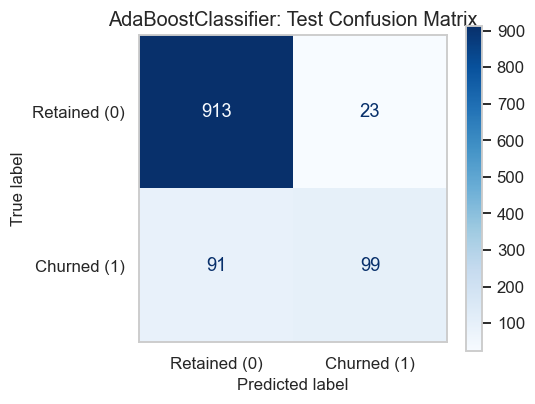

In [10]:
adaboost_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", AdaBoostClassifier(
        n_estimators=200,
        learning_rate=0.5,
        random_state=RANDOM_STATE,
    )),
])

adaboost_pipe.fit(X_train, y_train)
ada_pred = adaboost_pipe.predict(X_test)
ada_prob = adaboost_pipe.predict_proba(X_test)[:, 1]

ada_metrics = {
    "Accuracy": accuracy_score(y_test, ada_pred),
    "Precision": precision_score(y_test, ada_pred),
    "Recall": recall_score(y_test, ada_pred),
    "F1-Score": f1_score(y_test, ada_pred),
    "ROC-AUC": roc_auc_score(y_test, ada_prob),
}
print("AdaBoost Test Metrics:")
for k, v in ada_metrics.items():
    print(f"  {k:10s}: {v:.4f}")

print("\nClassification Report (AdaBoost):")
print(classification_report(y_test, ada_pred, target_names=["Retained (0)", "Churned (1)"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, ada_pred),
    display_labels=["Retained (0)", "Churned (1)"],
).plot(cmap="Blues", ax=ax, values_format="d")
ax.set_title("AdaBoostClassifier: Test Confusion Matrix")
ax.grid(False)
plt.tight_layout()
plt.show()


#### Analytical Question: What happens to the weights of misclassified instances from one iteration to the next in AdaBoost, and why?
In AdaBoost (Adaptive Boosting), each training instance starts with an equal weight $w_i = 1/N$. After weak learner $t$ is trained and evaluated (yielding weighted error $r_t$ and learner weight $\alpha_t = \eta \ln\frac{1 - r_t}{r_t}$), the weights of **misclassified instances are increased** (multiplied by $e^{\alpha_t}$ and renormalized), while correctly classified instances are down-weighted relatively.  
**Why:** Boosting trains predictors *sequentially* rather than independently; up-weighting misclassified samples forces the next weak learner ($t+1$) to concentrate on the hardest, previously missed boundary cases, progressively reducing ensemble **bias**.


In [11]:
base_lr = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
base_rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
base_svc = SVC(probability=True, random_state=RANDOM_STATE)

voting_hard_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", VotingClassifier(
        estimators=[("lr", base_lr), ("rf", base_rf), ("svc", base_svc)],
        voting="hard",
        n_jobs=-1,
    )),
])

voting_soft_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", VotingClassifier(
        estimators=[("lr", base_lr), ("rf", base_rf), ("svc", base_svc)],
        voting="soft",
        n_jobs=-1,
    )),
])

voting_hard_pipe.fit(X_train, y_train)
voting_soft_pipe.fit(X_train, y_train)

# Evaluate individual estimators + both voting ensembles
voting_rows = []
for est_name, est in [
    ("Individual: LogisticRegression", voting_soft_pipe.named_steps["classifier"].named_estimators_["lr"]),
    ("Individual: RandomForest", voting_soft_pipe.named_steps["classifier"].named_estimators_["rf"]),
    ("Individual: SVC (RBF)", voting_soft_pipe.named_steps["classifier"].named_estimators_["svc"]),
]:
    X_te_trans = voting_soft_pipe.named_steps["preprocessor"].transform(X_test)
    p = est.predict(X_te_trans)
    prob = est.predict_proba(X_te_trans)[:, 1]
    voting_rows.append({
        "Classifier": est_name,
        "Test_Accuracy": accuracy_score(y_test, p),
        "Test_Precision": precision_score(y_test, p),
        "Test_Recall": recall_score(y_test, p),
        "Test_F1": f1_score(y_test, p),
        "Test_ROC_AUC": roc_auc_score(y_test, prob),
    })

for v_name, v_pipe, has_prob in [
    ("VotingClassifier (voting='hard')", voting_hard_pipe, False),
    ("VotingClassifier (voting='soft')", voting_soft_pipe, True),
]:
    p = v_pipe.predict(X_test)
    prob = v_pipe.predict_proba(X_test)[:, 1] if has_prob else np.nan
    voting_rows.append({
        "Classifier": v_name,
        "Test_Accuracy": accuracy_score(y_test, p),
        "Test_Precision": precision_score(y_test, p),
        "Test_Recall": recall_score(y_test, p),
        "Test_F1": f1_score(y_test, p),
        "Test_ROC_AUC": roc_auc_score(y_test, prob) if has_prob else np.nan,
    })

voting_df = pd.DataFrame(voting_rows)
display(voting_df.round(4))


,Classifier,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC
0,Individual: LogisticRegression,0.8961,0.8349,0.4789,0.6087,0.8853
1,Individual: RandomForest,0.9805,0.9884,0.8947,0.9392,0.9981
2,Individual: SVC (RBF),0.8952,0.8529,0.4579,0.5959,0.9337
3,VotingClassifier (voting='hard'),0.9218,0.9397,0.5737,0.7124,NaN
4,VotingClassifier (voting='soft'),0.9307,0.9308,0.6368,0.7562,0.9804


Final Test-Set Performance Leaderboard:
                                Model  Test_Accuracy  Test_Precision  Test_Recall  Test_F1
   BaggingClassifier (bootstrap=True)         0.9867          0.9781       0.9421   0.9598
            Pasting (bootstrap=False)         0.9778          0.9365       0.9316   0.9340
              VotingClassifier (Soft)         0.9307          0.9308       0.6368   0.7562
              VotingClassifier (Hard)         0.9218          0.9397       0.5737   0.7124
                   AdaBoostClassifier         0.8988          0.8115       0.5211   0.6346
              LogisticRegression (L2)         0.8961          0.8349       0.4789   0.6087
DecisionTree (max_depth=1, High Bias)         0.8410          0.5240       0.6316   0.5728


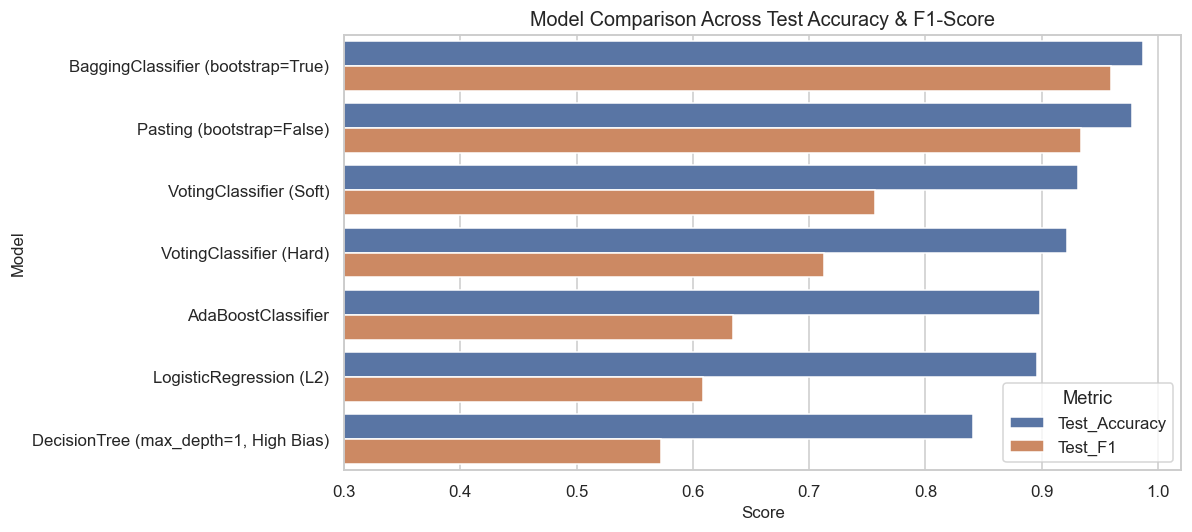

In [12]:
final_models = {
    "DecisionTree (max_depth=1, High Bias)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE)),
    ]).fit(X_train, y_train),
    "LogisticRegression (L2)": master_pipeline,
    "AdaBoostClassifier": adaboost_pipe,
    "BaggingClassifier (bootstrap=True)": bagging_pipe,
    "Pasting (bootstrap=False)": pasting_pipe,
    "VotingClassifier (Hard)": voting_hard_pipe,
    "VotingClassifier (Soft)": voting_soft_pipe,
}

final_rows = []
for name, mdl in final_models.items():
    p_te = mdl.predict(X_test)
    final_rows.append({
        "Model": name,
        "Test_Accuracy": accuracy_score(y_test, p_te),
        "Test_Precision": precision_score(y_test, p_te),
        "Test_Recall": recall_score(y_test, p_te),
        "Test_F1": f1_score(y_test, p_te),
    })

final_df = pd.DataFrame(final_rows).sort_values("Test_F1", ascending=False).reset_index(drop=True)
print("Final Test-Set Performance Leaderboard:")
print(final_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

fig, ax = plt.subplots(figsize=(11, 5))
melt_df = final_df.melt(id_vars="Model", value_vars=["Test_Accuracy", "Test_F1"], var_name="Metric", value_name="Score")
sns.barplot(data=melt_df, y="Model", x="Score", hue="Metric", ax=ax)
ax.set_title("Model Comparison Across Test Accuracy & F1-Score")
ax.set_xlim(0.3, 1.02)
plt.tight_layout()
plt.show()
